# Fourier Ring Correlation resolution estimation

Estimate single-image FRC resolution for a directory of hyperspectral images. Bands/Peaks may be evaluated in full or restricted to the top *N* images ranked by mean image intensity. For fair comparisons across conditions, create the peak-selection table from one reference dataset and pass its selected features e.g., m/z values to each condition.


## Configuration

Set `INPUT_DIR`, `PIXEL_SIZE_UM`, and `TOP_N`. Use `TOP_N = None` to process all valid images. `TOP_N = 100` processes the 100 peaks with the highest mean image intensity. Set `REFERENCE_SELECTION_CSV` to reuse a common selected m/z list from a reference condition.


In [29]:
from pathlib import Path
import re

import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from miplib.analysis.resolution import analysis as fsc_analysis
from miplib.analysis.resolution import fourier_ring_correlation
from miplib.data.containers.fourier_correlation_data import FourierCorrelationDataCollection
from miplib.data.containers.image import Image
from miplib.data.iterators.fourier_ring_iterators import FourierRingIterator
from miplib.processing import image as imops
from miplib.processing import windowing
from miplib.ui.cli import miplib_entry_point_options as options

INPUT_DIR = Path(r'E:/HyReS/results/DS brains/Images for clf/HyReS h5/brains4_top100')
OUTPUT_CSV = INPUT_DIR / 'FRC_resolutions.csv'
SELECTION_CSV = INPUT_DIR / 'FRC_peak_selection.csv'
PIXEL_SIZE_UM = 100.0
TOP_N = None                 # None = evaluate all peaks
REFERENCE_SELECTION_CSV = None  # e.g. Path(r'E:/.../reference_peak_selection.csv')
STRICT_CHANNEL_MATCH = True
IMAGE_EXTENSIONS = {'.tif', '.tiff', '.png'}
CHANNEL = 1              # None for grayscale/2D; integer for multichannel images
APPLY_HAMMING = True
AVERAGE_SPLITS = True

args_list = ("None --bin-delta=1  --frc-curve-fit-type=polynomial "
            " --resolution-threshold-criterion=half-bit").split()
args = options.get_frc_script_options(args_list)


## Helper functions


In [3]:
def natural_sort_key(path):
    """Sort peak2.tif before peak10.tif."""
    return [int(token) if token.isdigit() else token.lower()
            for token in re.split(r"(\d+)", path.name)]


def read_peak_image(path, channel=None):
    array = (imageio.imread(path))
#     array = np.asarray(imageio.imread(path), dtype=np.float64)
    if array.ndim == 3:
        if channel is None:
            raise ValueError(f"Multichannel image requires CHANNEL: {path.name}")
        array = array[..., channel]
    if array.ndim != 2:
        raise ValueError(f"Expected 2D image, got {array.shape}: {path.name}")
    return array


def collect_peak_metadata(directory):
    """Return naturally sorted files with a stable zero-based channel_index."""
    paths = sorted(
        (p for p in Path(directory).iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS),
        key=natural_sort_key,
    )
    if not paths:
        raise FileNotFoundError(f"No supported image files found in {directory}")

    records = []
    for channel_index, path in enumerate(paths):
        try:
            image = read_peak_image(path, CHANNEL)
            records.append({
                'channel_index': channel_index,
                'filename': path.name,
                'path': path,
                'mean_intensity': float(image.mean()),
                'max_intensity': float(image.max()),
                'n_pixels': int(image.size),
                'metadata_error': '',
            })
        except Exception as exc:
            records.append({
                'channel_index': channel_index,
                'filename': path.name,
                'path': path,
                'mean_intensity': np.nan,
                'max_intensity': np.nan,
                'n_pixels': np.nan,
                'metadata_error': str(exc),
            })
    return pd.DataFrame(records)


def select_peaks(peaks, top_n=None, reference_selection_csv=None, strict_channel_match=True):
    """Select top channels by mean intensity or transfer reference channel indices."""
    required = {'channel_index', 'filename', 'mean_intensity'}
    if not required.issubset(peaks.columns):
        raise ValueError(f"Missing required columns: {sorted(required - set(peaks.columns))}")

    peaks = peaks.sort_values('channel_index').reset_index(drop=True).copy()

    if reference_selection_csv is not None:
        reference = pd.read_csv(reference_selection_csv).copy()
        if 'channel_index' not in reference.columns:
            raise ValueError("Reference selection CSV must contain 'channel_index'.")
        reference['channel_index'] = reference['channel_index'].astype(int)
        if reference['channel_index'].duplicated().any():
            raise ValueError("Reference selection CSV contains duplicate channel indices.")

        target_indices = set(peaks['channel_index'])
        missing = sorted(set(reference['channel_index']) - target_indices)
        if missing:
            message = f"Missing reference indices in target dataset: {missing[:10]}" + ('...' if len(missing) > 10 else '')
            if strict_channel_match:
                raise IndexError(message)
            print('Warning:', message)
            reference = reference[reference['channel_index'].isin(target_indices)].copy()

        selected = reference.merge(
            peaks, on='channel_index', how='left', validate='one_to_one', suffixes=('_reference', '')
        )
        selected['reference_channel_index'] = selected['channel_index']
        selected['selection_source'] = 'reference_channel_index'
        return selected.reset_index(drop=True)

    ranked = peaks.dropna(subset=['mean_intensity']).sort_values(
        'mean_intensity', ascending=False, kind='stable'
    ).reset_index(drop=True)
    ranked['intensity_rank'] = np.arange(1, len(ranked) + 1)
    ranked['selection_source'] = 'all_channels' if top_n is None else f'top_{top_n}_mean_intensity'
    if top_n is None:
        return ranked
    if not isinstance(top_n, int) or isinstance(top_n, bool) or top_n < 1:
        raise ValueError('TOP_N must be a positive integer or None.')
    return ranked.head(top_n).reset_index(drop=True)


def estimate_frc_resolution(array, pixel_size_um):
    image = Image(array, [pixel_size_um, pixel_size_um])
    if APPLY_HAMMING and not args.disable_hamming:
        image = Image(windowing.apply_hamming_window(image), image.spacing)
    image = imops.zero_pad_to_cube(image)

    image1, image2 = imops.checkerboard_split(image)
    image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)
    frc_data = FourierCorrelationDataCollection()
    task = fourier_ring_correlation.FRC(
        image1, image2, FourierRingIterator(image1.shape, args.d_bin)
    )
    frc_data[0] = task.execute()

    if AVERAGE_SPLITS:
        image1, image2 = imops.reverse_checkerboard_split(image)
        image1, image2 = imops.zero_pad_to_matching_shape(image1, image2)
        task = fourier_ring_correlation.FRC(
            image1, image2, FourierRingIterator(image1.shape, args.d_bin)
        )
        frc_data[0].correlation['correlation'] *= 0.5
        frc_data[0].correlation['correlation'] += task.execute().correlation['correlation'] * 0.5


    analyzer = fsc_analysis.FourierCorrelationAnalysis(frc_data, image.spacing[0], args)
    results = analyzer.execute(z_correction=0)
    result = results[0]
    
    resolution = result.resolution['resolution']
    point = result.resolution['resolution-point']
    cutoff = float(point[1]) if point is not None else np.nan
    return float(resolution) if resolution is not None else np.nan, cutoff


## Rank peaks and choose the evaluation set

`mean_intensity` is computed from each raw peak image before FRC calculation. Save this table and reuse it as `REFERENCE_SELECTION_CSV` when comparing e.g. GT, LR, HyReS-restored datasets.


In [30]:
all_peaks = collect_peak_metadata(INPUT_DIR)
selected_peaks = select_peaks(
    all_peaks,
    top_n=TOP_N,
    reference_selection_csv=REFERENCE_SELECTION_CSV,
    strict_channel_match=STRICT_CHANNEL_MATCH,
)

selected_peaks.drop(columns='path').to_csv(SELECTION_CSV, index=False)
print(f'Found {len(all_peaks)} files.')
print(f'Selected {len(selected_peaks)} channels using: {selected_peaks.selection_source.iloc[0]}')
print(f'Selection table saved to: {SELECTION_CSV}')
selected_peaks[['channel_index', 'intensity_rank', 'mean_intensity', 'filename']].head(10)


Found 100 files.
Selected 100 channels using: all_channels
Selection table saved to: E:\HyReS\results\DS brains\Images for clf\HyReS h5\brains4_top100\FRC_peak_selection.csv


,channel_index,intensity_rank,mean_intensity,filename
0,8,1,41.302719,214.0588.tif
1,10,2,37.854170,242.0889.tif
2,29,3,35.560009,716.5521.tif
3,2,4,32.681740,130.0627.tif
4,24,5,32.214381,553.2804.tif
5,3,6,31.769720,132.0419.tif
6,6,7,31.145463,174.0514.tif
7,23,8,30.955977,552.2765.tif
8,1,9,30.724097,128.0471.tif
9,5,10,30.353213,146.0573.tif


## Evaluate selected channels/peaks


In [31]:
records = []
for _, peak in selected_peaks.iterrows():
    try:
        image = read_peak_image(peak.path, CHANNEL)
        resolution_um, cutoff_frequency = estimate_frc_resolution(image, PIXEL_SIZE_UM)
        records.append({
            **peak.drop(labels='path').to_dict(),
            'cutoff_frequency': cutoff_frequency,
            'estimated_resolution_um': resolution_um,
            'status': 'ok',
            'error': '',
        })
    except Exception as exc:
        records.append({
            **peak.drop(labels='path').to_dict(),
            'cutoff_frequency': np.nan,
            'estimated_resolution_um': np.nan,
            'status': 'failed',
            'error': str(exc),
        })

results = pd.DataFrame(records)
results.to_csv(OUTPUT_CSV, index=False)
results.head()


C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\Hy

C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\Hy

C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\HyReS\Git\HyReS\miplib\analysis\resolution\analysis.py:173: RankWarning: Polyfit may be poorly conditioned
  frc_eq = fit_frc_curve(data_set, degree, fit_type)
C:\Users\yx2011\Box\Publications\Hy

,channel_index,filename,mean_intensity,max_intensity,n_pixels,metadata_error,intensity_rank,selection_source,cutoff_frequency,estimated_resolution_um,status,error
0,8,214.0588.tif,41.302719,255.0,1171456,,1,all_channels,0.703009,284.491375,ok,
1,10,242.0889.tif,37.854170,255.0,1171456,,2,all_channels,0.689463,290.081023,ok,
2,29,716.5521.tif,35.560009,255.0,1171456,,3,all_channels,0.735010,272.105043,ok,
3,2,130.0627.tif,32.681740,255.0,1171456,,4,all_channels,0.724321,276.120622,ok,
4,24,553.2804.tif,32.214381,255.0,1171456,,5,all_channels,0.734199,272.405560,ok,


## Summary and plots


Evaluated: 100 peaks
Successful: 100 peaks
Failed: 0 peaks
Mean resolution: 256.32 µm
Median resolution: 256.55 µm


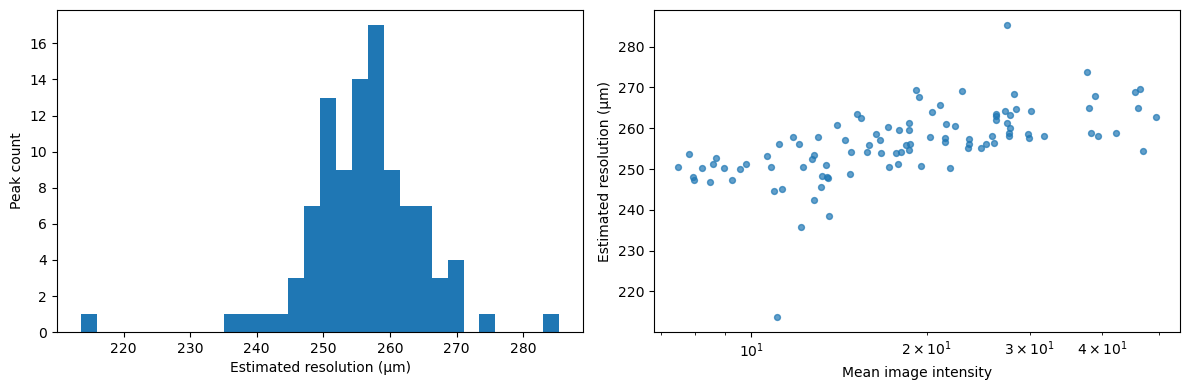

In [28]:
valid = results.loc[results.status.eq('ok') & results.estimated_resolution_um.notna()].copy()
print(f'Evaluated: {len(results)} peaks')
print(f'Successful: {len(valid)} peaks')
print(f'Failed: {len(results) - len(valid)} peaks')
if not valid.empty:
    print(f'Mean resolution: {valid.estimated_resolution_um.mean():.2f} µm')
    print(f'Median resolution: {valid.estimated_resolution_um.median():.2f} µm')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(valid['estimated_resolution_um'].dropna(), bins=30)
axes[0].set(xlabel='Estimated resolution (µm)', ylabel='Peak count')
axes[1].scatter(valid['mean_intensity'], valid['estimated_resolution_um'], s=18, alpha=0.7)
axes[1].set(xlabel='Mean image intensity', ylabel='Estimated resolution (µm)')
axes[1].set_xscale('log')
plt.tight_layout()
plt.show()


## Optional: inspect one peak

Set `EXAMPLE_MZ` to a selected m/z value. This plot is only for inspection and does not alter the batch results.


In [ ]:
EXAMPLE_MZ = None  # e.g. 128.0471

if EXAMPLE_MZ is not None:
    match = selected_peaks.iloc[(selected_peaks['m.z'] - EXAMPLE_MZ).abs().argsort()[:1]]
    peak = match.iloc[0]
    array = read_peak_image(peak.path, CHANNEL)
    resolution_um, cutoff_frequency, result = estimate_frc_resolution(
        array, PIXEL_SIZE_UM, args, APPLY_HAMMING, AVERAGE_SPLITS
    )
    plt.figure(figsize=(5, 4))
    plt.imshow(array, cmap='gray')
    plt.title(f"m/z {peak['m.z']:.4f}; FRC resolution {resolution_um:.2f} µm")
    plt.axis('off')
    plt.show()

    plt.figure(figsize=(5, 3))
    plt.plot(result.correlation['frequency'], result.correlation['correlation'])
    plt.plot(result.correlation['frequency'], result.resolution['threshold'])
    plt.xlabel('Spatial frequency')
    plt.ylabel('FRC')
    plt.tight_layout()
    plt.show()
